<a href="https://colab.research.google.com/github/Fanelp58/applied_ml_at_scale/blob/project/ML_at_scale.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [10]:
import csv
import os
import math
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import numpy as np

# export folder
FIG_DIR = "/content/drive/My Drive/MovieLens/figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_pdf(fig, name):
    """Exports a figure as an individual PDF"""
    path = os.path.join(FIG_DIR, f"{name}.pdf")
    fig.savefig(path, format="pdf", bbox_inches="tight")

RATINGS_CSV = "/content/drive/My Drive/MovieLens/ratings.csv"
MOVIES_CSV  = "/content/drive/My Drive/MovieLens/movies.csv"

# vectorizers initialization
rating_values_counter = Counter()
movie_stats           = defaultdict(lambda: [0, 0.0])  # movieId -> [count, sum]
user_rating_count     = Counter()          # userId  -> nb ratings
n_rows                = 0

with open(RATINGS_CSV, mode="r", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    for row in reader:
        r = float(row["rating"])
        rating_values_counter[r] += 1

        mid = row["movieId"]
        movie_stats[mid][0] += 1
        movie_stats[mid][1] += r
        user_rating_count[row["userId"]] += 1
        n_rows += 1

print(f"Number of rows : {n_rows:,}")
print(f"Number of distincts movies         : {len(movie_stats):,}")
print(f"Number of distincts users         : {len(user_rating_count):,}")

Number of rows : 32,000,204
Number of distincts movies         : 84,432
Number of distincts users         : 200,948


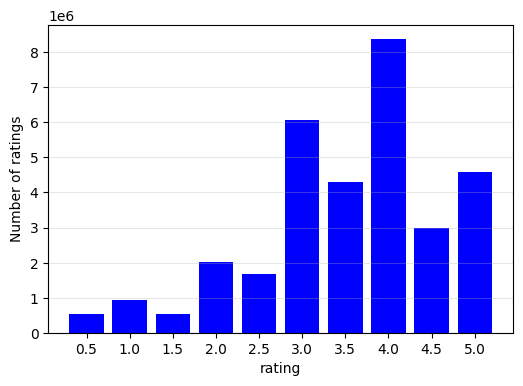

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
ratings_sorted = sorted(rating_values_counter.items())
vals  = [v for _, v in ratings_sorted]
labs  = [str(k) for k, _ in ratings_sorted]
ax.bar(labs, vals, color="blue")
ax.set_xlabel("rating"); ax.set_ylabel("Number of ratings")
ax.grid(axis="y", alpha=0.3)
save_pdf(fig, "eda_01_ratings_distribution")
plt.show()

Top 10 best-rated movies (≥ 1000 ratings) :
  4.447  (1,956 ratings)  Planet Earth II (2016)
  4.444  (2,948 ratings)  Planet Earth (2006)
  4.427  (2,811 ratings)  Band of Brothers (2001)
  4.405  (102,929 ratings)  Shawshank Redemption, The (1994)
  4.317  (66,440 ratings)  Godfather, The (1972)
  4.312  (11,670 ratings)  Parasite (2019)
  4.300  (1,163 ratings)  Blue Planet II (2017)
  4.299  (1,140 ratings)  Twin Peaks (1989)
  4.265  (21,863 ratings)  12 Angry Men (1957)
  4.265  (67,750 ratings)  Usual Suspects, The (1995)


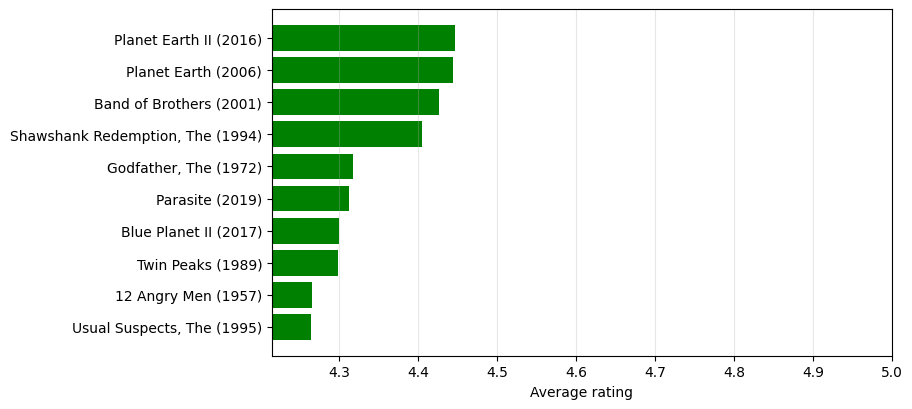

In [4]:
# load movies titles from movies.csv
id_to_title = {}
with open(MOVIES_CSV, mode="r", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    for row in reader:
        id_to_title[row["movieId"]] = row["title"]

MIN_RATINGS_TOP = 1000

# (mean, count, title) for movies with count >= threshold
top_candidates = []
for mid, (cnt, s) in movie_stats.items():
    if cnt >= MIN_RATINGS_TOP:
        top_candidates.append((s / cnt, cnt, id_to_title.get(mid, mid)))

top_candidates.sort(key=lambda t: (-t[0], -t[1]))
top10 = top_candidates[:10]

print(f"Top 10 best-rated movies (≥ {MIN_RATINGS_TOP} ratings) :")
for mean, cnt, title in top10:
    print(f"  {mean:.3f}  ({cnt:,} ratings)  {title}")

# horizontal Plot
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = [t[2] for t in top10][::-1]
means  = [t[0] for t in top10][::-1]
ax.barh(labels, means, color="green")
ax.set_xlabel("Average rating")
ax.set_xlim(min(means) - 0.05, 5.0)
ax.grid(axis="x", alpha=0.3)
save_pdf(fig, "eda_03_top10_best_rated")
plt.show()

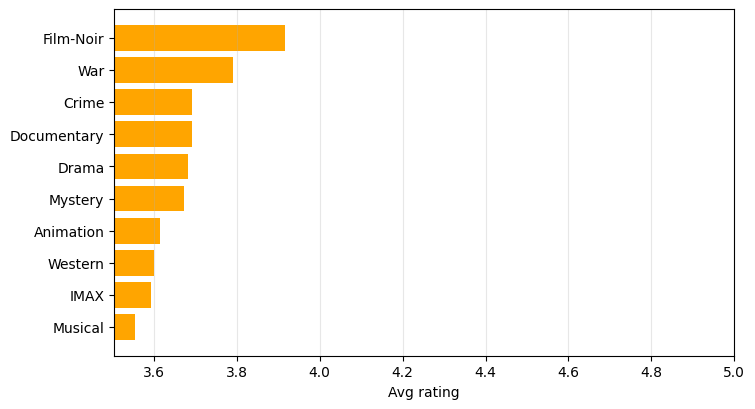

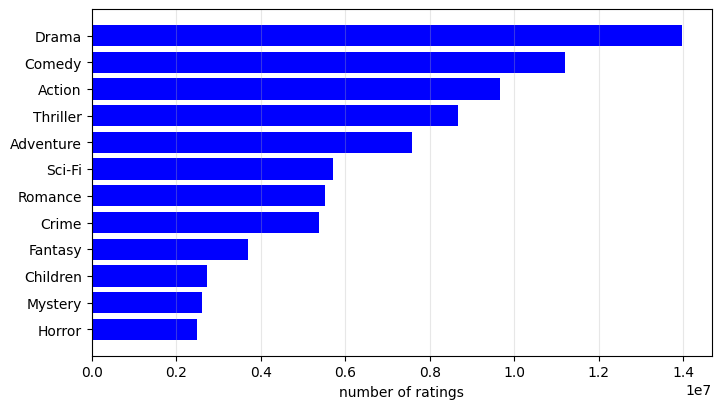

In [11]:
# Load movies genres by movieId
genres_by_movie = {}
with open(MOVIES_CSV, mode="r", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    for row in reader:
        genres_by_movie[row["movieId"]] = row["genres"].split("|")

# by genre
genre_stats = defaultdict(lambda: [0, 0.0])   # genre -> [count, sum]
for mid, (cnt, s) in movie_stats.items():
    for g in genres_by_movie.get(mid, []):
        genre_stats[g][0] += cnt
        genre_stats[g][1] += s

# average + count per genre
genre_rows = [(g, c, s / c) for g, (c, s) in genre_stats.items() if c > 0]

# best rated genre (count >= 10_000)
MIN_GENRE = 10_000
best_genres = sorted(
    [r for r in genre_rows if r[1] >= MIN_GENRE],
    key=lambda r: -r[2])[:10]

fig, ax = plt.subplots(figsize=(8, 4.5))
labs = [r[0] for r in best_genres][::-1]
mns  = [r[2] for r in best_genres][::-1]
ax.barh(labs, mns, color="orange")
ax.set_xlabel("Avg rating")
ax.set_xlim(min(mns) - 0.05, 5.0)
ax.grid(axis="x", alpha=0.3)
save_pdf(fig, "eda_04_top10_genres_best_rated")
plt.show()

# Most frequent genres by nb of ratings
most_genres = sorted(genre_rows, key=lambda r: -r[1])[:12]
fig, ax = plt.subplots(figsize=(8, 4.5))
labs = [r[0] for r in most_genres][::-1]
cnts = [r[1] for r in most_genres][::-1]
ax.barh(labs, cnts, color="blue")
ax.set_xlabel("number of ratings")
ax.grid(axis="x", alpha=0.3)
save_pdf(fig, "eda_05_top12_genres_most_frequent")
plt.show()

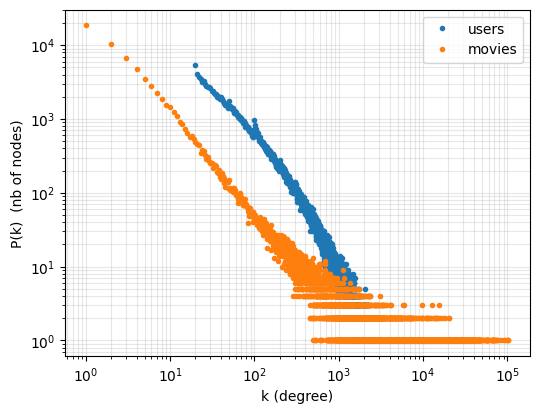

In [12]:
user_deg_counter  = Counter(user_rating_count.values())
movie_deg_counter = Counter(cnt for cnt, _ in movie_stats.values())

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.loglog(list(user_deg_counter.keys()),  list(user_deg_counter.values()),
          "o", ms=3, label="users")
ax.loglog(list(movie_deg_counter.keys()), list(movie_deg_counter.values()),
          "o", ms=3, label="movies")
ax.set_xlabel("k (degree)"); ax.set_ylabel("P(k)  (nb of nodes)")
ax.grid(alpha=0.3, which="both")
ax.legend()
save_pdf(fig, "eda_06_power_law_degrees")
plt.show()

**SPLIT Train/Test**

In [1]:

import csv
import random

random.seed(42)

user_index  = {}
movie_index = {}
user_ratings_dict = {}

with open("/content/drive/My Drive/MovieLens/ratings.csv", mode="r", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    for row in reader:
        u_id = row["userId"]
        m_id = row["movieId"]
        r    = float(row["rating"])
        if u_id not in user_index:
            user_index[u_id]  = len(user_index)
        if m_id not in movie_index:
            movie_index[m_id] = len(movie_index)
        u_idx = user_index[u_id]
        m_idx = movie_index[m_id]
        user_ratings_dict.setdefault(u_idx, []).append((m_idx, r))

raw_ratings_train = []
raw_ratings_test  = []

for u_idx, ratings in user_ratings_dict.items():
    n = len(ratings)
    split_idx = int(0.8 * n)
    for m_idx, r in ratings[:split_idx]:
        raw_ratings_train.append((u_idx, m_idx, r))
    for m_idx, r in ratings[split_idx:]:
        raw_ratings_test.append((u_idx, m_idx, r))

num_users  = len(user_index)
num_movies = len(movie_index)

print(f"Users  : {num_users:,}")
print(f"Movies : {num_movies:,}")
print(f"Train  : {len(raw_ratings_train):,}")
print(f"Test   : {len(raw_ratings_test):,}")

Users  : 200,948
Movies : 84,432
Train  : 25,520,897
Test   : 6,479,307


In [2]:
from collections import Counter
import matplotlib.pyplot as plt

sum_train_ratings = 0.0
total_train_ratings = 0.0

data_by_user_train = [[] for _ in range(num_users)]
data_by_movie_train = [[] for _ in range(num_movies)]
data_by_user_test = [[] for _ in range(num_users)]

for u_idx, m_idx, r in raw_ratings_train:
    data_by_user_train[u_idx].append((m_idx, r))
    data_by_movie_train[m_idx].append((u_idx, r))
    sum_train_ratings += r
    total_train_ratings += 1

for u_idx, m_idx, r in raw_ratings_test:
    data_by_user_test[u_idx].append((m_idx, r))

# Practical 2

**ALS only biases, vectorized version**

In [3]:

import numpy as np
import math
import matplotlib.pyplot as plt
import os

FIG_DIR = "/content/drive/My Drive/MovieLens/figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_pdf(fig, name):
    path = os.path.join(FIG_DIR, f"{name}.pdf")
    fig.savefig(path, format="pdf", bbox_inches="tight")


def train_bias_only_vectorized(reg, data_by_user_train, data_by_movie_train, num_epochs=50, data_by_user_test=None, seed=0):
    """
    only *_train serves for optimization ; *_test for evaluattion
    """
    num_users  = len(data_by_user_train)
    num_movies = len(data_by_movie_train)

    b_u = np.zeros(num_users)
    b_i = np.zeros(num_movies)

    # vectorizers
    user_m = [None] * num_users
    user_r = [None] * num_users
    for u, ratings in enumerate(data_by_user_train):
        if ratings:
            arr = np.asarray(ratings, dtype=np.float64)
            user_m[u] = arr[:, 0].astype(np.int64)
            user_r[u] = arr[:, 1]

    item_u = [None] * num_movies
    item_r = [None] * num_movies
    for m, ratings in enumerate(data_by_movie_train):
        if ratings:
            arr = np.asarray(ratings, dtype=np.float64)
            item_u[m] = arr[:, 0].astype(np.int64)
            item_r[m] = arr[:, 1]

    # evaluation vectorized
    def eval_split(by_user, m_arr_list, r_arr_list):
        sse, n = 0.0, 0
        for u in range(len(by_user)):
            m_ids = m_arr_list[u]
            if m_ids is None:
                continue
            r_true = r_arr_list[u]
            pred = b_u[u] + b_i[m_ids]
            sse += np.sum((r_true - pred) ** 2)
            n   += len(r_true)
        return (math.sqrt(sse / n) if n else float("nan")), sse, n

    if data_by_user_test is not None:
        test_m = [None] * len(data_by_user_test)
        test_r = [None] * len(data_by_user_test)
        for u, ratings in enumerate(data_by_user_test):
            if ratings:
                arr = np.asarray(ratings, dtype=np.float64)
                test_m[u] = arr[:, 0].astype(np.int64)
                test_r[u] = arr[:, 1]

    hist = {"train_rmse": [], "test_rmse": [], "nll": []}

    for _ in range(num_epochs):

        #USER PASS
        for u in range(num_users):
            m_ids = user_m[u]
            if m_ids is None:
                continue
            r_true = user_r[u]
            n_u    = len(r_true)
            resid  = r_true - b_i[m_ids]
            b_u[u] = resid.sum() / (n_u + reg)

        #ITEM PASS
        for m in range(num_movies):
            u_ids = item_u[m]
            if u_ids is None:
                continue
            r_true = item_r[m]
            n_m    = len(r_true)
            resid  = r_true - b_u[u_ids]
            b_i[m] = resid.sum() / (n_m + reg)

        # diagnostics
        tr_rmse, sse_tr, _ = eval_split(data_by_user_train, user_m, user_r)
        hist["train_rmse"].append(tr_rmse)
        hist["nll"].append(0.5 * sse_tr + 0.5 * reg * (b_u @ b_u + b_i @ b_i))
        if data_by_user_test is not None:
            te_rmse, _, _ = eval_split(data_by_user_test, test_m, test_r)
            hist["test_rmse"].append(te_rmse)

    return b_u, b_i, hist


# Train
REG_P2 = 0.1
EPOCHS_P2 = 30

print(f"ALS with only biases and λ={REG_P2}, {EPOCHS_P2} epochs")
b_u, b_i, hist_p2 = train_bias_only_vectorized(
    reg=REG_P2,
    data_by_user_train=data_by_user_train,
    data_by_movie_train=data_by_movie_train,
    num_epochs=EPOCHS_P2,
    data_by_user_test=data_by_user_test,
    seed=0)

print(f"Final train RMSE : {hist_p2['train_rmse'][-1]:.4f}")
print(f"Final test  RMSE : {hist_p2['test_rmse'][-1]:.4f}")

ALS with only biases and λ=0.1, 30 epochs
Final train RMSE : 0.8419
Final test  RMSE : 0.8916


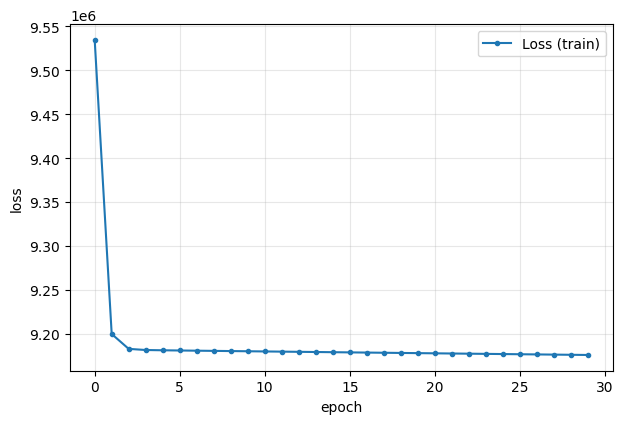

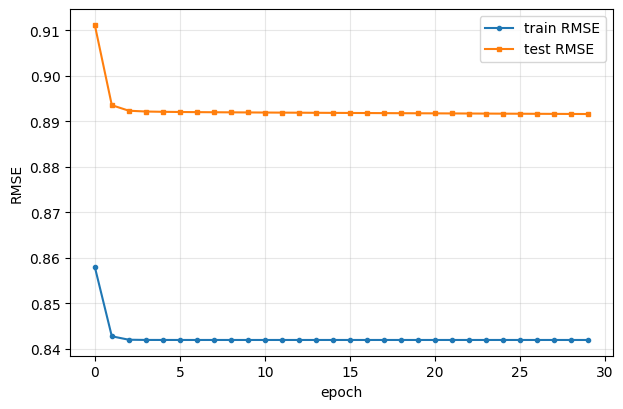

In [4]:
# loss function = neg.log.likelihood
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(hist_p2["nll"], marker="o", ms=3, label="Loss (train)")
ax.set_xlabel("epoch"); ax.set_ylabel("loss")
ax.grid(alpha=0.3); ax.legend()
save_pdf(fig, "p2_loss_nll")
plt.show()


# RMSE train vs test
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(hist_p2["train_rmse"], marker="o", ms=3, label="train RMSE")
ax.plot(hist_p2["test_rmse"],  marker="s", ms=3, label="test RMSE")
ax.set_xlabel("epoch"); ax.set_ylabel("RMSE")
ax.grid(alpha=0.3); ax.legend()
save_pdf(fig, "p2_rmse_train_test")
plt.show()

# Practical 3

**Model, loss, ALS all vectorized**

In [4]:
import numpy as np
import math
import matplotlib.pyplot as plt
import os

FIG_DIR = "/content/drive/My Drive/MovieLens/figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_pdf(fig, name):
    path = os.path.join(FIG_DIR, f"{name}.pdf")
    fig.savefig(path, format="pdf", bbox_inches="tight")


def train_mf_vectorized(k, reg, data_by_user_train, data_by_movie_train,
                        num_epochs=30, data_by_user_test=None, seed=0):
    """
    ALS for matrix facto with biaises and latent factors
    """
    num_users  = len(data_by_user_train)
    num_movies = len(data_by_movie_train)

    rng = np.random.default_rng(seed)
    U   = rng.normal(scale=0.1, size=(num_users,  k))
    V   = rng.normal(scale=0.1, size=(num_movies, k))
    b_u = np.zeros(num_users)
    b_i = np.zeros(num_movies)
    I_k = np.identity(k)

    # vectorizers
    user_m = [None] * num_users
    user_r = [None] * num_users
    for u, ratings in enumerate(data_by_user_train):
        if ratings:
            arr = np.asarray(ratings, dtype=np.float64)
            user_m[u] = arr[:, 0].astype(np.int64)
            user_r[u] = arr[:, 1]

    item_u = [None] * num_movies
    item_r = [None] * num_movies
    for m, ratings in enumerate(data_by_movie_train):
        if ratings:
            arr = np.asarray(ratings, dtype=np.float64)
            item_u[m] = arr[:, 0].astype(np.int64)
            item_r[m] = arr[:, 1]

    def eval_split(by_user, m_arr_list, r_arr_list):
        sse, n = 0.0, 0
        for u in range(len(by_user)):
            m_ids = m_arr_list[u]
            if m_ids is None:
                continue
            r_true = r_arr_list[u]
            pred = b_u[u] + b_i[m_ids] + V[m_ids] @ U[u]
            sse += np.sum((r_true - pred) ** 2)
            n   += len(r_true)
        return (math.sqrt(sse / n) if n else float("nan")), sse, n

    if data_by_user_test is not None:
        test_m = [None] * len(data_by_user_test)
        test_r = [None] * len(data_by_user_test)
        for u, ratings in enumerate(data_by_user_test):
            if ratings:
                arr = np.asarray(ratings, dtype=np.float64)
                test_m[u] = arr[:, 0].astype(np.int64)
                test_r[u] = arr[:, 1]

    hist = {"train_rmse": [], "test_rmse": [], "nll": []}

    # ALS loop
    for _ in range(num_epochs):

        # USER PASS
        for u in range(num_users):
            m_ids = user_m[u]
            if m_ids is None:
                continue
            r_true = user_r[u]
            n_u    = len(r_true)

            # bias
            V_u   = V[m_ids]
            resid = r_true - b_i[m_ids] - V_u @ U[u]
            b_u[u] = resid.sum() / (n_u + reg)

            # latent vector U
            resid = r_true - b_u[u] - b_i[m_ids]
            A     = reg * I_k + V_u.T @ V_u
            rhs   = V_u.T @ resid
            U[u]  = np.linalg.solve(A, rhs)

        # ITEM PASS
        for m in range(num_movies):
            u_ids = item_u[m]
            if u_ids is None:
                continue
            r_true = item_r[m]
            n_m    = len(r_true)

            # bias
            U_m   = U[u_ids]
            resid = r_true - b_u[u_ids] - U_m @ V[m]
            b_i[m] = resid.sum() / (n_m + reg)

            # latent vector V
            resid = r_true - b_i[m] - b_u[u_ids]
            A     = reg * I_k + U_m.T @ U_m
            rhs   = U_m.T @ resid
            V[m]  = np.linalg.solve(A, rhs)

        # diagnostics
        tr_rmse, sse_tr, _ = eval_split(data_by_user_train, user_m, user_r)
        hist["train_rmse"].append(tr_rmse)
        hist["nll"].append(0.5 * sse_tr + 0.5 * reg *
                           (b_u @ b_u + b_i @ b_i + np.sum(U*U) + np.sum(V*V)))
        if data_by_user_test is not None:
            te_rmse, _, _ = eval_split(data_by_user_test, test_m, test_r)
            hist["test_rmse"].append(te_rmse)

    return b_u, b_i, U, V, hist

**Main training and plots**

Final train RMSE : 0.6908
Final test  RMSE : 0.8950


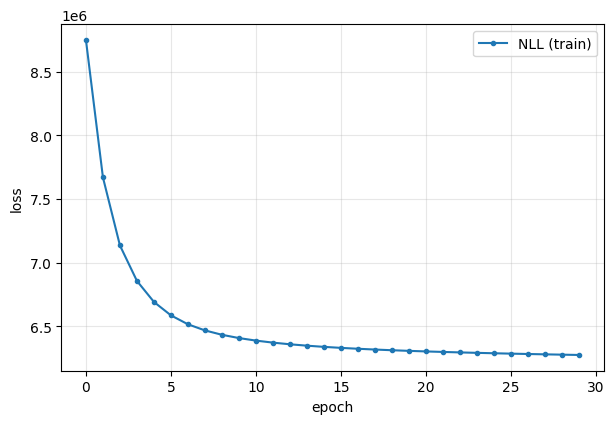

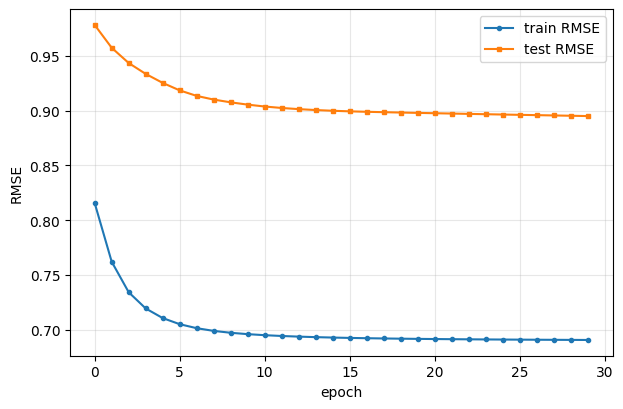

In [8]:

K_MAIN        = 10
LAMBDA_MAIN   = 0.1
EPOCHS_MAIN   = 30


b_u, b_i, U, V, hist = train_mf_vectorized(
    k=K_MAIN, reg=LAMBDA_MAIN,
    data_by_user_train=data_by_user_train,
    data_by_movie_train=data_by_movie_train,
    num_epochs=EPOCHS_MAIN,
    data_by_user_test=data_by_user_test,
    seed=0)

print(f"Final train RMSE : {hist['train_rmse'][-1]:.4f}")
print(f"Final test  RMSE : {hist['test_rmse'][-1]:.4f}")

# Loss function
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(hist["nll"], marker="o", ms=3, label="NLL (train)")
ax.set_xlabel("epoch"); ax.set_ylabel("loss")
ax.grid(alpha=0.3); ax.legend()
save_pdf(fig, "p3_loss_nll")
plt.show()

#RMSE train vs test
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(hist["train_rmse"], marker="o", ms=3, label="train RMSE")
ax.plot(hist["test_rmse"],  marker="s", ms=3, label="test RMSE")
ax.set_xlabel("epoch"); ax.set_ylabel("RMSE")
ax.grid(alpha=0.3); ax.legend()
save_pdf(fig, "p3_rmse_train_test")
plt.show()

**K-sweep**

K=10  train=0.6930  test=0.8999  (451.5s)
K=20  train=0.6354  test=0.9524  (737.6s)
overall sweep K : 1210.3s


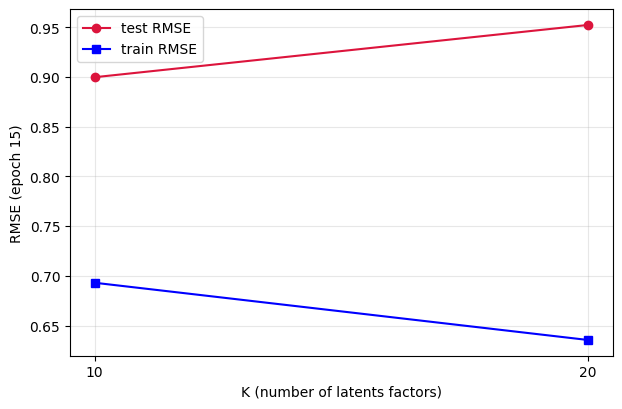

In [5]:
import time
import gc

K_GRID          = [10, 20]
SWEEP_EPOCHS    = 15
SWEEP_LAMBDA    = 0.1
sweep_k_results = {}

t_all = time.time()
for k_val in K_GRID:
    t0 = time.time()
    _, _, _, _, h = train_mf_vectorized(
        k=k_val, reg=SWEEP_LAMBDA,
        data_by_user_train=data_by_user_train,
        data_by_movie_train=data_by_movie_train,
        num_epochs=SWEEP_EPOCHS,
        data_by_user_test=data_by_user_test, seed=0)
    sweep_k_results[k_val] = h
    print(f"K={k_val:2d}  train={h['train_rmse'][-1]:.4f}  "
          f"test={h['test_rmse'][-1]:.4f}  ({time.time()-t0:.1f}s)")
    gc.collect()
print(f"overall sweep K : {time.time()-t_all:.1f}s")

test_final  = [sweep_k_results[k]["test_rmse"][-1]  for k in K_GRID]
train_final = [sweep_k_results[k]["train_rmse"][-1] for k in K_GRID]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(K_GRID, test_final,  marker="o", ms=6, label="test RMSE",  color="crimson")
ax.plot(K_GRID, train_final, marker="s", ms=6, label="train RMSE", color="blue")
ax.set_xlabel("K (number of latents factors)")
ax.set_ylabel(f"RMSE (epoch {SWEEP_EPOCHS})")
ax.set_xticks(K_GRID)
ax.grid(alpha=0.3); ax.legend()
save_pdf(fig, "p3_sweep_K")
plt.show()

**λ-sweep with K fixed at the best value from the K-sweep**

K_BEST selected for the λ sweep : 10
λ=0.01   train=0.6939  test=1.0534
λ=0.1    train=0.6930  test=0.8999
λ=1.0    train=0.6967  test=0.8524


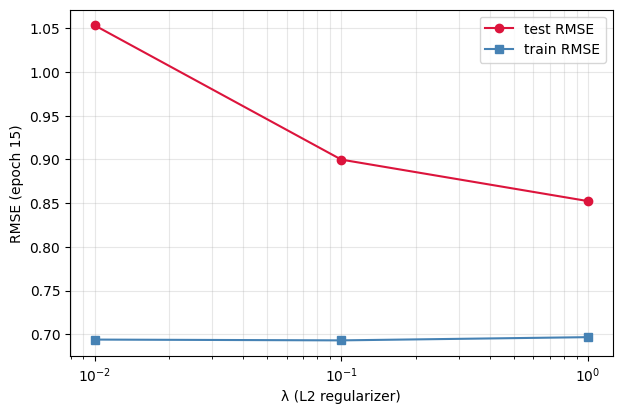

In [6]:

K_BEST = min(zip(K_GRID, test_final), key=lambda x: x[1])[0]
print(f"K_BEST selected for the λ sweep : {K_BEST}")

LAMBDA_GRID       = [0.01, 0.1, 1.0]
SWEEP_LAM_EPOCHS  = 15
sweep_lam_results = {}

for lam in LAMBDA_GRID:
    _, _, _, _, h = train_mf_vectorized(
        k=K_BEST, reg=lam,
        data_by_user_train=data_by_user_train,
        data_by_movie_train=data_by_movie_train,
        num_epochs=SWEEP_LAM_EPOCHS,
        data_by_user_test=data_by_user_test, seed=0)
    sweep_lam_results[lam] = h
    print(f"λ={lam:<5}  train={h['train_rmse'][-1]:.4f}  "
          f"test={h['test_rmse'][-1]:.4f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(LAMBDA_GRID, [sweep_lam_results[l]["test_rmse"][-1]  for l in LAMBDA_GRID],
        marker="o", ms=6, label="test RMSE",  color="crimson")
ax.plot(LAMBDA_GRID, [sweep_lam_results[l]["train_rmse"][-1] for l in LAMBDA_GRID],
        marker="s", ms=6, label="train RMSE", color="steelblue")
ax.set_xscale("log")
ax.set_xlabel("λ (L2 regularizer)")
ax.set_ylabel(f"RMSE (epoch {SWEEP_LAM_EPOCHS})")
ax.grid(alpha=0.3, which="both"); ax.legend()
save_pdf(fig, "p3_sweep_lambda")
plt.show()

**PRACTICAL 4**

**Final training with best (K, λ) from Practical 3**

In [7]:

K_FINAL = K_BEST       # from K sweep
LAMBDA_FIN = min(LAMBDA_GRID, key=lambda l: sweep_lam_results[l]["test_rmse"][-1])     # from lambda sweep

b_u, b_i, U, V, hist_final = train_mf_vectorized(
    k=K_FINAL, reg=LAMBDA_FIN,
    data_by_user_train=data_by_user_train,
    data_by_movie_train=data_by_movie_train,
    num_epochs=30,
    data_by_user_test=data_by_user_test,
    seed=0)

print(f"Practical 4 model: K={K_FINAL}, λ={LAMBDA_FIN}")
print(f"Train RMSE : {hist_final['train_rmse'][-1]:.4f}")
print(f"Test  RMSE : {hist_final['test_rmse'][-1]:.4f}")

Practical 4 model: K=10, λ=1.0
Train RMSE : 0.6954
Test  RMSE : 0.8571
